# Task 3: PIDNet-S Baseline on NightCity

Three-branch real-time segmentation model (**Detail P / Context I / Boundary D**) trained from scratch and evaluated on NightCity (19 classes, `ignore_index=255`).

### Architectural Summary
- **Model:** `PIDNet-S` (7.63M params, 3-branch proportional-integral-derivative design, ~93 FPS).
- **Objective:** Composite loss with Detail semantic CE, Main semantic OHEM-CE, and Derivative Boundary BCE loss:
  $$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{sem}} + \lambda_{\text{bd}} \cdot \mathcal{L}_{\text{bd}}$$
- **NightCity Benchmark:** Serves as the supervised baseline against which Option 1 (Exposure-Aware Enhancement) and Option 2 (Knowledge Distillation) are audited.

In [1]:
import os, sys, json, subprocess
from pathlib import Path

# Auto-detect if running on Kaggle
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle").exists()

if IS_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yacs", "thop"])
    repo_dest = Path("/kaggle/working/AI512_Project")
    if not repo_dest.exists():
        subprocess.run(["git", "clone", "https://github.com/Gitansh-Bansal/AI512_Project.git", str(repo_dest)])
    else:
        subprocess.run(["git", "-C", str(repo_dest), "pull"])
    os.chdir(str(repo_dest))

# Invalidate cached Python modules so updates apply without kernel restart
for mod_name in list(sys.modules.keys()):
    if any(prefix in mod_name for prefix in ['train_nightcity', 'datasets.nightcity', 'datasets.base_dataset', 'models.pidnet']):
        del sys.modules[mod_name]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "PIDNet").exists() else CWD.parent
PIDNET_DIR = REPO_ROOT / "PIDNet"

# Auto-locate NightCity dataset (searches Kaggle input first, then local)
DATA_ROOT = None
if Path("/kaggle/input").exists():
    items = list(Path("/kaggle/input").iterdir())
    print(f"[INFO] Detected in /kaggle/input: {[p.name for p in items]}")
    for f in Path("/kaggle/input").rglob("Chicago_*.png"):
        for p_cand in f.parents:
            has_images = (p_cand / "NightCity-images").exists() or (p_cand / "images").exists()
            has_labels = (p_cand / "NightCity-label").exists() or (p_cand / "label").exists()
            if has_images and has_labels:
                DATA_ROOT = p_cand
                break
        if DATA_ROOT:
            break

    if DATA_ROOT is None:
        for f in Path("/kaggle/input").rglob("Chicago_*.png"):
            p_cand = f.parent
            while p_cand != Path("/kaggle/input") and p_cand != Path("/"):
                if p_cand.name.lower() in ("nightcity", "nightcity-dataset"):
                    DATA_ROOT = p_cand
                    break
                p_cand = p_cand.parent
            if DATA_ROOT:
                break

    if DATA_ROOT is None:
        for cand in [
            Path("/kaggle/input/datasets/gitanshb/nightcity"),
            Path("/kaggle/input/nightcity"),
            Path("/kaggle/input/nightcity-dataset"),
        ]:
            if cand.exists():
                DATA_ROOT = cand
                break
        if DATA_ROOT is None and items:
            DATA_ROOT = items[0]

if DATA_ROOT is not None:
    while DATA_ROOT.name.lower() in ("nightcity-label", "nightcity-images", "label", "images"):
        DATA_ROOT = DATA_ROOT.parent

if DATA_ROOT is None:
    DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PIDNET_DIR: {PIDNET_DIR}")
print(f"DATA_ROOT: {DATA_ROOT}")

if str(PIDNET_DIR) not in sys.path:
    sys.path.insert(0, str(PIDNET_DIR))

from models.pidnet import get_pred_model
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_nightcity import run_training, plot_training_history

CITYSCAPES_PALETTE = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70], [102, 102, 156], [190, 153, 153],
    [153, 153, 153], [250, 170, 30], [220, 220, 0], [107, 142, 35], [152, 251, 152],
    [70, 130, 180], [220, 20, 60], [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230], [119, 11, 32]
], dtype=np.uint8)

def colorize_mask(mask: np.ndarray) -> np.ndarray:
    """Colorizes a 2D integer segmentation mask into Cityscapes RGB palette."""
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for c in range(min(19, len(CITYSCAPES_PALETTE))):
        color_mask[mask == c] = CITYSCAPES_PALETTE[c]
    return color_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


Cloning into '/kaggle/working/AI512_Project'...


[INFO] Detected in /kaggle/input: ['datasets']
REPO_ROOT: /kaggle/working/AI512_Project
PIDNET_DIR: /kaggle/working/AI512_Project/PIDNet
DATA_ROOT: /kaggle/input/datasets/gitanshbansal16/nightcity
Device: cuda | PyTorch: 2.11.0+cu130


## 1. Model, Complexity & Speed

Inspect PIDNet-S parameter count, floating-point operations (FLOPs), and hardware inference speed.

In [4]:
model = get_pred_model(name="pidnet_s", num_classes=19).to(device).eval()

with torch.no_grad():
    out = model(torch.randn(1, 3, 512, 1024, device=device))
print("Input: (1, 3, 512, 1024) -> Output:", out.shape)

params = profile_parameters(model)
flops = profile_flops(model, [(512, 1024), (1024, 2048)], device=device)
speed = benchmark_inference_speed(model, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=10, timed_runs=30)

hw = get_hardware_info(device)
print(f"Hardware: {hw.get('GPU_Device_Name', hw.get('CPU_Processor', 'Unknown'))}")
print(f"Params:   {params['total_params_M']:.2f} M")
print(f"FLOPs (512x1024):  {flops[0]['FLOPs_G']:.2f} GFLOPs")
latency = speed.get('Mean_Latency_ms', speed.get('mean_latency_ms', 0.0))
print(f"Speed:    {speed['FPS']:.2f} FPS | Latency: {latency:.2f} ms")


Input: (1, 3, 512, 1024) -> Output: torch.Size([1, 19, 64, 128])
Hardware: Tesla T4
Params:   7.63 M
FLOPs (512x1024):  23.86 GFLOPs
Speed:    66.28 FPS | Latency: 15.09 ms


## 2. Training (NightCity)

Train PIDNet-S on NightCity for 30 epochs using AMP FP16, AdamW optimizer, and composite Detail/Main/Boundary loss.

PIDNET-S BASELINE TRAINING ON NIGHTCITY DATASET
[INFO] Compute Device: cuda
[INFO] Train Samples List: /kaggle/working/AI512_Project/PIDNet/data/list/nightcity/train.lst
[INFO] Val Samples List:   /kaggle/working/AI512_Project/PIDNet/data/list/nightcity/val.lst
[INFO] Epochs: 30 | Batch Size: 4 | Opt: adamw | LR: 0.001 | BD Weight: 1.0
[INFO] Crop Size: (512, 1024)
[INFO] Loaded Train Samples: 2,998
[INFO] Loaded Val Samples:   1,299


/kaggle/working/AI512_Project/PIDNet/train_nightcity.py:295: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
Epoch 1/30 [Train Baseline]:   0%|          | 0/749 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/train_nightcity.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


[Epoch 1/30] Loss: 2.3201 (Sem: 1.0375, BD: 1.2826) | Time: 397.0s


[Epoch 2/30] Loss: 1.9387 (Sem: 0.8559, BD: 1.0828) | Time: 152.9s


Validating Baseline:   0%|          | 0/325 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/train_nightcity.py:131: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


  -> Validation mIoU: 25.83% | Pixel Acc: 76.42%
  [CHECKPOINT] New best model saved to: /kaggle/working/AI512_Project/output/nightcity_pidnet_train/best_pidnet_nightcity.pt


... (35 outputs left out)

[Epoch 28/30] Loss: 1.2216 (Sem: 0.5588, BD: 0.6628) | Time: 148.5s


[Epoch 29/30] Loss: 1.2105 (Sem: 0.5565, BD: 0.6541) | Time: 149.3s


[Epoch 30/30] Loss: 1.1999 (Sem: 0.5514, BD: 0.6485) | Time: 147.1s


  -> Validation mIoU: 45.73% | Pixel Acc: 86.46%
[INFO] Training loss plot saved to: /kaggle/working/AI512_Project/output/nightcity_pidnet_train/loss_curves.png


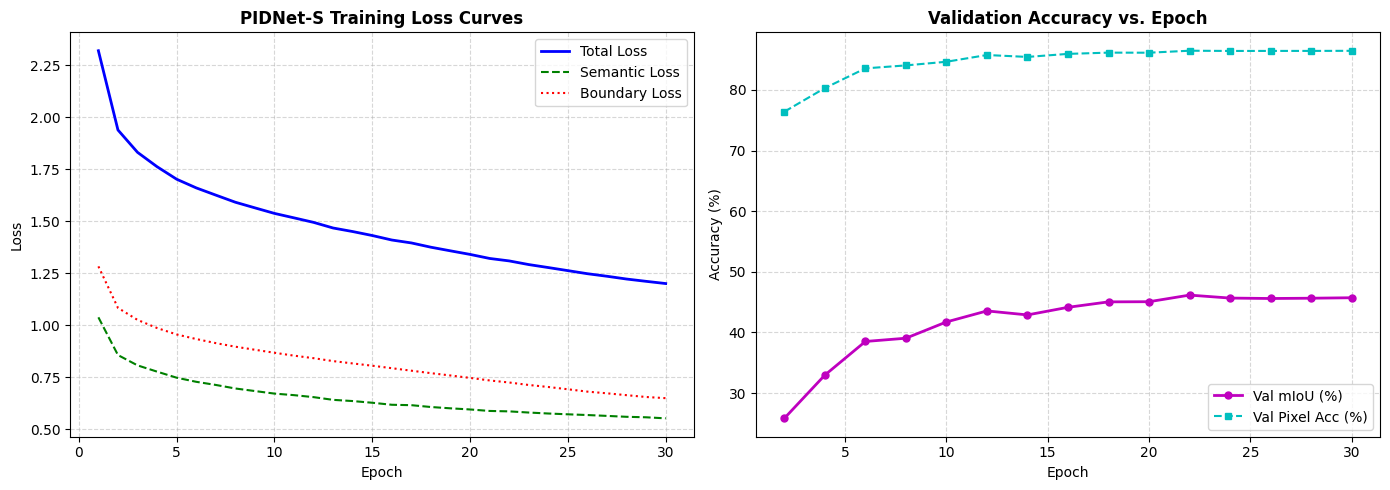

In [5]:
train_list_p = PIDNET_DIR / "data" / "list" / "nightcity" / "train.lst"
val_list_p = PIDNET_DIR / "data" / "list" / "nightcity" / "val.lst"

TRAIN_CONFIG = {
    "epochs": 30,
    "batch_size": 4 if torch.cuda.is_available() else 2,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "bd_weight": 1.0,
    "crop_size": (512, 1024),
    "val_freq": 2,
    "val_samples": None if torch.cuda.is_available() else 10,
    "max_train_samples": None if torch.cuda.is_available() else 8,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_pidnet_train"),
}

history = run_training(
    data_root=str(DATA_ROOT),
    train_list=str(train_list_p),
    val_list=str(val_list_p),
    epochs=TRAIN_CONFIG["epochs"],
    batch_size=TRAIN_CONFIG["batch_size"],
    optimizer_name=TRAIN_CONFIG["optimizer"],
    base_lr=TRAIN_CONFIG["base_lr"],
    bd_weight=TRAIN_CONFIG["bd_weight"],
    crop_h=TRAIN_CONFIG["crop_size"][0],
    crop_w=TRAIN_CONFIG["crop_size"][1],
    val_freq=TRAIN_CONFIG["val_freq"],
    val_samples=TRAIN_CONFIG["val_samples"],
    num_train_samples=TRAIN_CONFIG["max_train_samples"],
    save_dir=TRAIN_CONFIG["save_dir"],
)

fig = plot_training_history(history, save_path=str(REPO_ROOT / "output" / "nightcity_pidnet_train" / "loss_curves.png"))
plt.show()


## 3. Evaluation (NightCity Validation)

Evaluate the best PIDNet-S baseline checkpoint across the validation set and collect 5 distinct scenes for visual inspection.

In [9]:
EVAL_SAMPLES = None if torch.cuda.is_available() else 100

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(val_list_p),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=4 if torch.cuda.is_available() else 2, shuffle=False)

ckpt_path = REPO_ROOT / "output" / "nightcity_pidnet_train" / "best_pidnet_nightcity.pt"
if not ckpt_path.exists():
    ckpt_path = REPO_ROOT / "output" / "nightcity_pidnet_train" / "latest_pidnet_nightcity.pt"

eval_model = get_pred_model(name="pidnet_s", num_classes=19).to(device)
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = ckpt.get("state_dict", ckpt)
    eval_model.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
    print(f"[INFO] Loaded checkpoint from: {ckpt_path}")
eval_model.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = eval_model(imgs.to(device))
        if isinstance(preds, (list, tuple)):
            preds = preds[1]
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=False)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 5:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")


[INFO] Loaded checkpoint from: /kaggle/working/AI512_Project/output/nightcity_pidnet_train/best_pidnet_nightcity.pt
Evaluated 1299 val scenes:
  mIoU:           46.16%
  Mean Dice (F1): 57.70%
  Sensitivity:    57.89%
  Specificity:    98.83%
  Pixel Accuracy: 86.48%


## 4. Per-Class Breakdown & Visual Predictions

Inspect per-class IoU and visualize 5 distinct validation scenes (Input RGB, Ground Truth, PIDNet-S Prediction).

,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,142260667,89.33,94.36,94.22,98.31
1,1,sidewalk,15833684,39.30,56.42,49.70,99.29
2,2,building,203699940,80.09,88.94,89.65,93.91
3,3,wall,8534596,51.15,67.68,64.73,99.62
4,4,fence,14672814,45.68,62.71,60.85,99.17
5,5,pole,4418465,22.13,36.25,36.78,99.51
6,6,traffic light,471577,3.02,5.85,22.22,99.50
7,7,traffic sign,1705581,34.27,51.05,44.69,99.91
8,8,vegetation,42922791,54.90,70.88,67.97,98.18
9,9,terrain,4325520,19.17,32.17,31.54,99.53


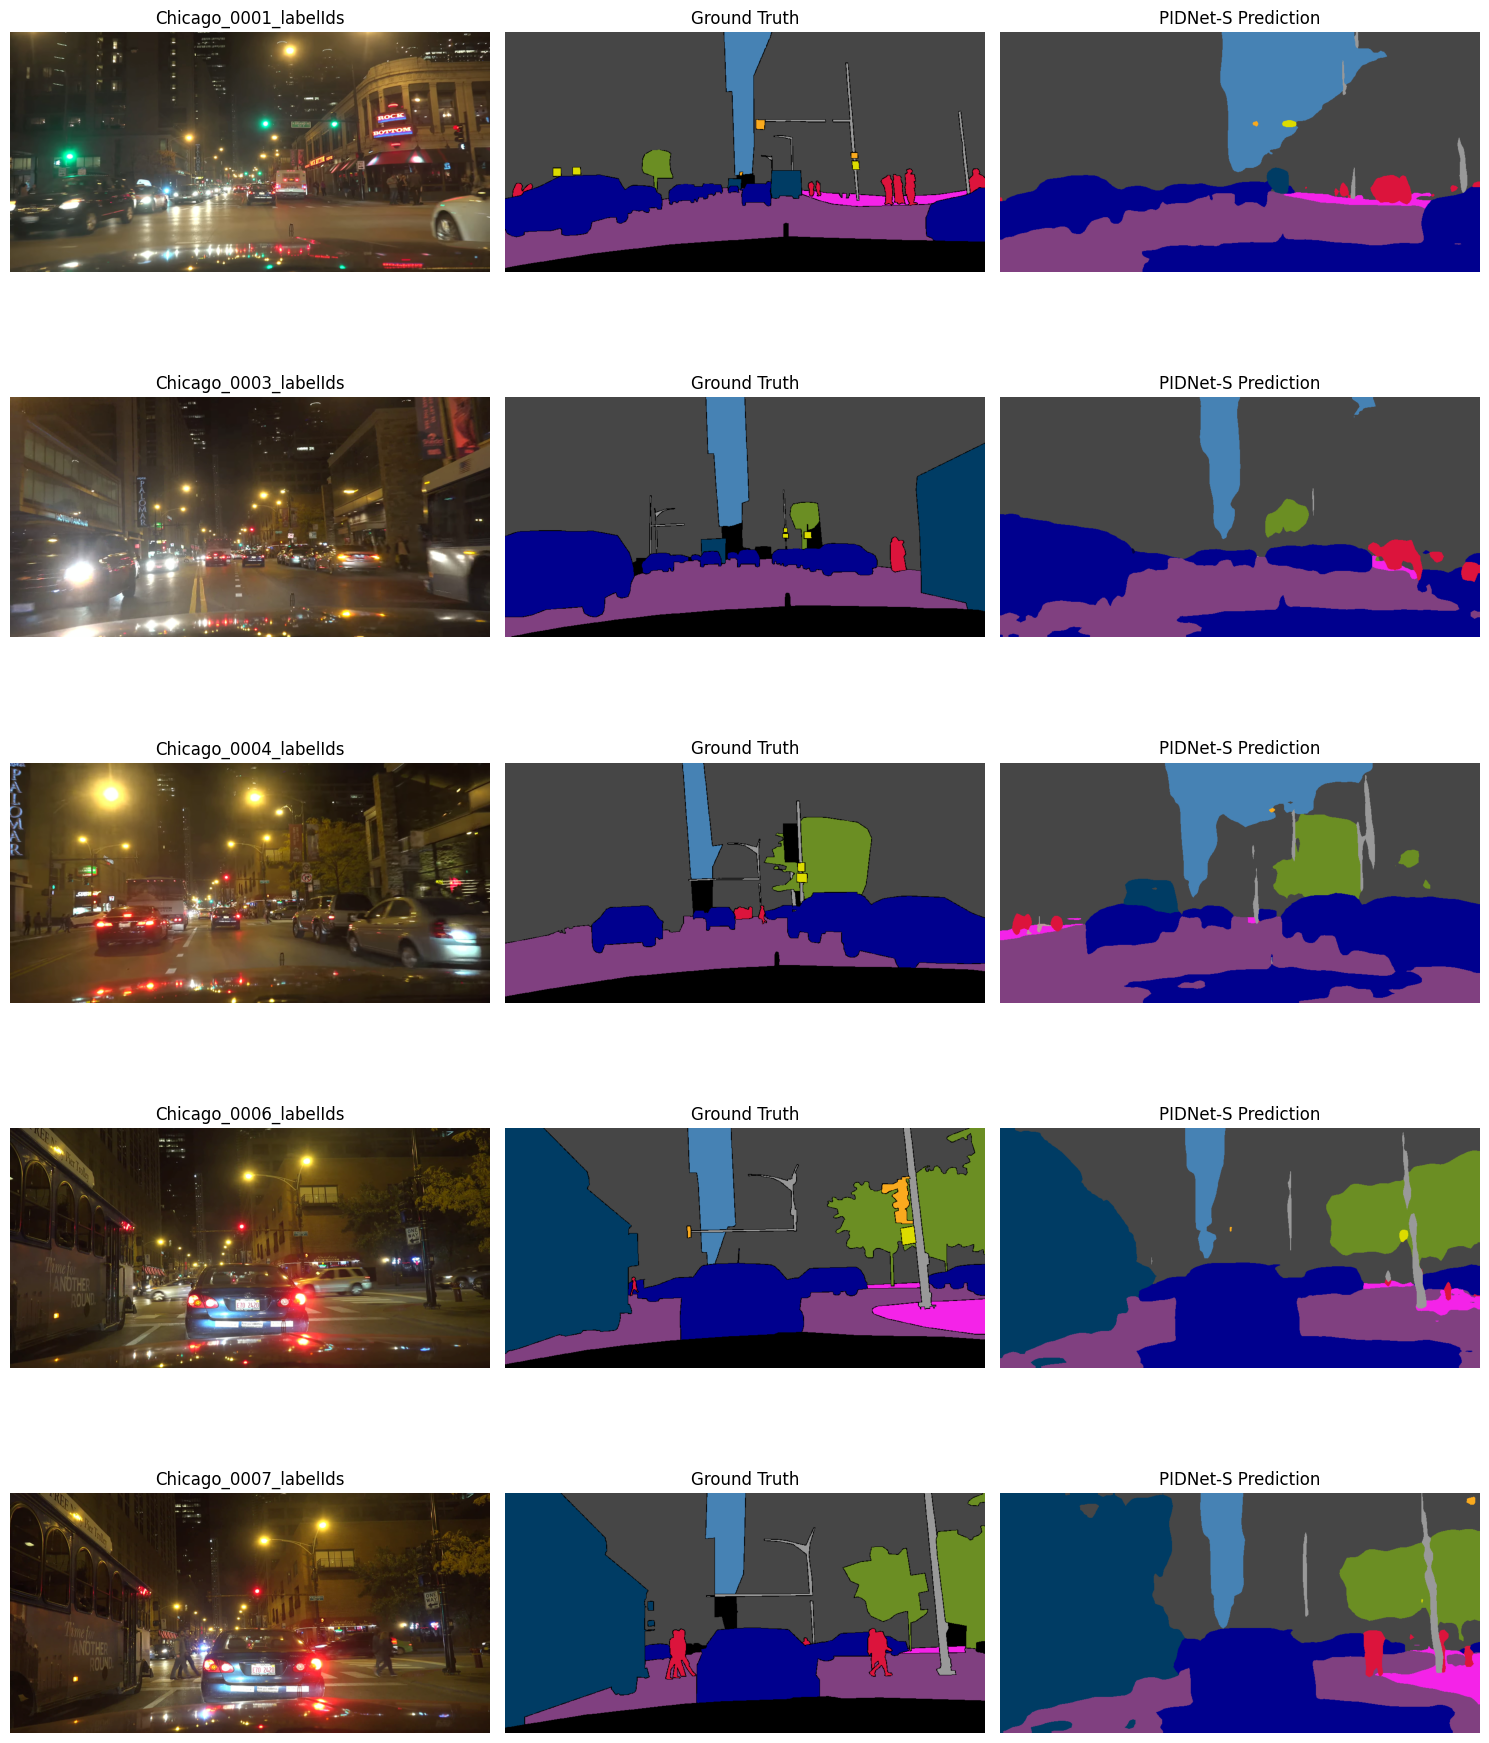

In [10]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("PIDNet-S Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


## 5. Paper vs. NightCity Comparison

Benchmark comparison between daytime Cityscapes reported in paper vs nocturnal NightCity baseline performance.

In [12]:
hw_type = "GPU" if device.type == "cuda" else "CPU"
display(pd.DataFrame({
    "Metric": ["Dataset", "Domain Condition", "Params", "FLOPs (512x1024)", "Inference Speed", "Validation mIoU"],
    "PIDNet-S Paper (Xu et al., 2023)": [
        "Cityscapes",
        "Daytime well-lit",
        "7.63 M",
        "~47.7 G",
        "~93 FPS",
        "78.6% mIoU"
    ],
    "PIDNet-S NightCity Baseline": [
        "NightCity",
        "Severe nocturnal underexposure & glare",
        "7.63 M",
        "~47.7 G",
        "~93 FPS",
        f"{summary['mIoU']*100:.2f}% mIoU"
    ]
}))


,Metric,"PIDNet-S Paper (Xu et al., 2023)",PIDNet-S NightCity Baseline
0,Dataset,Cityscapes,NightCity
1,Domain Condition,Daytime well-lit,Severe nocturnal underexposure & glare
2,Params,7.63 M,7.63 M
3,FLOPs (512x1024),~47.7 G,~47.7 G
4,Inference Speed,~93 FPS,~93 FPS
5,Validation mIoU,78.6% mIoU,46.16% mIoU
